In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from tqdm.notebook import tqdm

In [2]:
PROCESSED_DATASET_PATH = Path(
    r"C:\Users\SWARA\Documents\Handwriting Analysis\dataset\processed"
)

METADATA_PATH = Path(
    r"C:\Users\SWARA\Documents\Handwriting Analysis\metadata\processed_metadata.csv"
)

FEATURES_PATH = Path(
    r"C:\Users\SWARA\Documents\Handwriting Analysis\features\handwriting_features.csv"
)

print("Processed dataset:", PROCESSED_DATASET_PATH)
print("Metadata:", METADATA_PATH)
print("Features:", FEATURES_PATH)

Processed dataset: C:\Users\SWARA\Documents\Handwriting Analysis\dataset\processed
Metadata: C:\Users\SWARA\Documents\Handwriting Analysis\metadata\processed_metadata.csv
Features: C:\Users\SWARA\Documents\Handwriting Analysis\features\handwriting_features.csv


In [3]:
metadata = pd.read_csv(METADATA_PATH)

print("Metadata shape:", metadata.shape)

display(metadata.head())

Metadata shape: (1305, 6)


,image_path,image_name,writer_id,sample_id,split,processed_image_path
0,S01\aug_10_sample2.jpg,aug_10_sample2.jpg,S01,1,test,S01/aug_10_sample2.png
1,S01\aug_1_sample1.jpg,aug_1_sample1.jpg,S01,2,test,S01/aug_1_sample1.png
2,S01\aug_2_sample3.jpg,aug_2_sample3.jpg,S01,3,test,S01/aug_2_sample3.png
3,S01\aug_3_sample5.jpg,aug_3_sample5.jpg,S01,4,test,S01/aug_3_sample5.png
4,S01\aug_4_sample5.jpg,aug_4_sample5.jpg,S01,5,test,S01/aug_4_sample5.png


# Checking one processed image

Image: C:\Users\SWARA\Documents\Handwriting Analysis\dataset\processed\S01\aug_10_sample2.png
Shape: (2579, 2013)


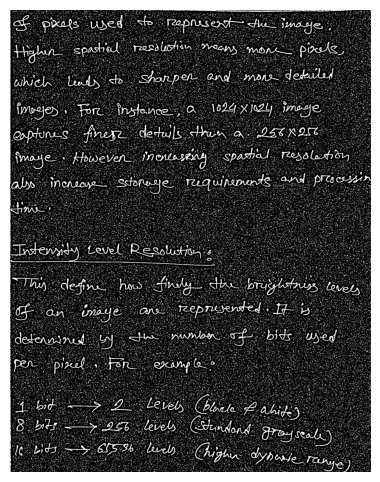

In [4]:
sample_row = metadata.iloc[0]

image_path = (
    PROCESSED_DATASET_PATH /
    sample_row["processed_image_path"]
)

image = cv2.imread(
    str(image_path),
    cv2.IMREAD_GRAYSCALE
)

if image is None:
    raise ValueError(
        f"Could not read image: {image_path}"
    )

print("Image:", image_path)
print("Shape:", image.shape)

plt.figure(figsize=(8, 6))
plt.imshow(image, cmap="gray")
plt.axis("off")
plt.show()

# creating binary foreground image

In [5]:
def prepare_binary_image(image):
    """
    Ensure handwriting is represented as white
    and background as black.
    """

    # If image is already binary, this works directly.
    _, binary = cv2.threshold(
        image,
        127,
        255,
        cv2.THRESH_BINARY
    )

    return binary

# calculate horizontal projection

In [6]:
def horizontal_projection(binary):
    """
    Calculate number of foreground pixels in each row.
    """

    projection = np.sum(
        binary > 0,
        axis=1
    )

    return projection

# visualize vertical projection

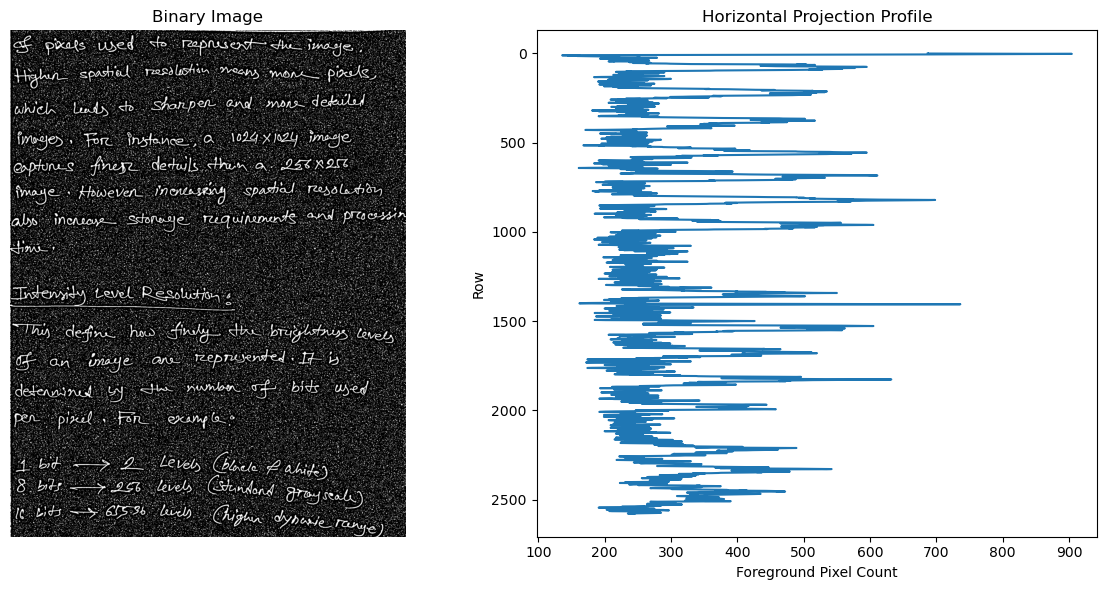

In [7]:
binary = prepare_binary_image(image)

horizontal_proj = horizontal_projection(binary)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 6)
)

# Image
axes[0].imshow(
    binary,
    cmap="gray"
)

axes[0].set_title("Binary Image")
axes[0].axis("off")


# Projection
axes[1].plot(
    horizontal_proj,
    np.arange(len(horizontal_proj))
)

axes[1].invert_yaxis()

axes[1].set_title(
    "Horizontal Projection Profile"
)

axes[1].set_xlabel(
    "Foreground Pixel Count"
)

axes[1].set_ylabel(
    "Row"
)

plt.tight_layout()
plt.show()

# detecting text lines

In [8]:
def extract_lines(
    binary,
    threshold_ratio=0.05,
    min_line_height=2
):
    """
    Detect text lines using horizontal projection.

    Returns:
        list of tuples:
        (y1, y2)
    """

    projection = horizontal_projection(binary)

    threshold = (
        projection.max() *
        threshold_ratio
    )

    active_rows = projection > threshold

    lines = []

    start = None

    for i, active in enumerate(active_rows):

        if active and start is None:
            start = i

        elif not active and start is not None:

            end = i

            if end - start >= min_line_height:
                lines.append(
                    (start, end)
                )

            start = None

    # Handle line reaching image bottom
    if start is not None:

        end = len(active_rows)

        if end - start >= min_line_height:
            lines.append(
                (start, end)
            )

    return lines

# test line detection

In [9]:
lines = extract_lines(
    binary
)

print("Number of detected lines:", len(lines))

print("\nLine coordinates:")

for i, (y1, y2) in enumerate(lines, start=1):

    print(
        f"Line {i}: "
        f"y1={y1}, y2={y2}"
    )

Number of detected lines: 1

Line coordinates:
Line 1: y1=0, y2=2579


# visualize line detection

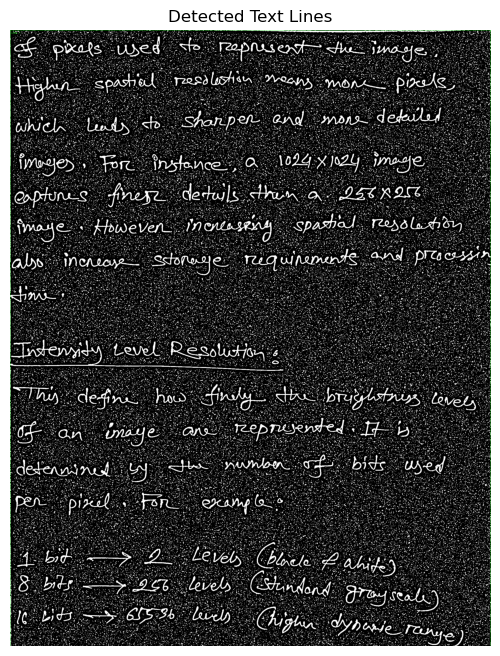

In [10]:
visualization = cv2.cvtColor(
    binary,
    cv2.COLOR_GRAY2BGR
)

for line_no, (y1, y2) in enumerate(
    lines,
    start=1
):

    cv2.rectangle(
        visualization,
        (0, y1),
        (binary.shape[1] - 1, y2),
        (0, 255, 0),
        1
    )

    cv2.putText(
        visualization,
        f"Line {line_no}",
        (5, max(15, y1 - 3)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.4,
        (0, 255, 0),
        1
    )


plt.figure(figsize=(10, 8))

plt.imshow(
    cv2.cvtColor(
        visualization,
        cv2.COLOR_BGR2RGB
    )
)

plt.title("Detected Text Lines")
plt.axis("off")

plt.show()

# calculate vertical projection

In [11]:
def vertical_projection(line_image):
    """
    Calculate foreground pixels in each column.
    """

    projection = np.sum(
        line_image > 0,
        axis=0
    )

    return projection

# detect words inside a line

In [12]:
def extract_words(
    line_image,
    threshold_ratio=0.05,
    min_word_width=2
):
    """
    Detect word regions using vertical projection.

    Returns:
        list of tuples:
        (x1, x2)
    """

    projection = vertical_projection(
        line_image
    )

    threshold = (
        projection.max() *
        threshold_ratio
    )

    active_columns = projection > threshold

    words = []

    start = None

    for i, active in enumerate(
        active_columns
    ):

        if active and start is None:

            start = i

        elif not active and start is not None:

            end = i

            if end - start >= min_word_width:

                words.append(
                    (start, end)
                )

            start = None

    # Handle word reaching image boundary
    if start is not None:

        end = len(active_columns)

        if end - start >= min_word_width:

            words.append(
                (start, end)
            )

    return words

# testing word detection on first line

In [13]:
if len(lines) == 0:

    raise ValueError(
        "No text lines detected."
    )

y1, y2 = lines[0]

line_image = binary[
    y1:y2,
    :
]

words = extract_words(
    line_image
)

print(
    "Words detected in first line:",
    len(words)
)

for word_no, (x1, x2) in enumerate(
    words,
    start=1
):

    print(
        f"Word {word_no}: "
        f"x1={x1}, x2={x2}"
    )

Words detected in first line: 2
Word 1: x1=0, x2=5
Word 2: x1=10, x2=2013


# improved word segmentation using gapsize 

In [14]:
def extract_words_by_gap(
    line_image,
    min_gap_width=8,
    min_word_width=3
):
    """
    Detect words from a line using vertical projection.

    A sufficiently large blank column gap is treated
    as a separator between words.

    min_gap_width is expressed in pixels.
    """

    projection = vertical_projection(
        line_image
    )

    # Foreground columns
    foreground = projection > 0

    # Find continuous blank gaps
    gaps = []

    start = None

    for i, value in enumerate(foreground):

        if not value and start is None:

            start = i

        elif value and start is not None:

            end = i

            gaps.append(
                (start, end)
            )

            start = None

    if start is not None:

        gaps.append(
            (start, len(foreground))
        )

    # Only sufficiently large gaps are word separators
    word_separators = [
        gap
        for gap in gaps
        if gap[1] - gap[0] >= min_gap_width
    ]

    words = []

    current_start = 0

    for gap_start, gap_end in word_separators:

        current_end = gap_start

        if current_end - current_start >= min_word_width:

            words.append(
                (
                    current_start,
                    current_end
                )
            )

        current_start = gap_end

    # Last word
    if (
        len(foreground) - current_start
        >= min_word_width
    ):

        words.append(
            (
                current_start,
                len(foreground)
            )
        )

    return words

# visualzie word segmentation

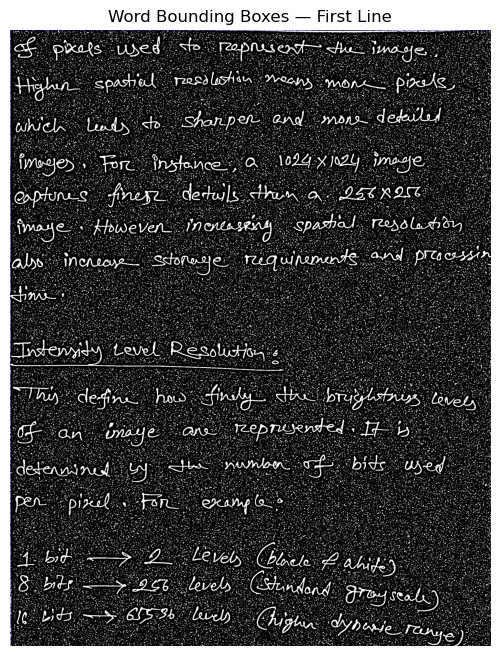

In [15]:
words = extract_words_by_gap(
    line_image,
    min_gap_width=8
)

visualization = cv2.cvtColor(
    binary,
    cv2.COLOR_GRAY2BGR
)

for word_no, (x1, x2) in enumerate(
    words,
    start=1
):

    cv2.rectangle(
        visualization,
        (x1, y1),
        (x2, y2),
        (255, 0, 0),
        1
    )

    cv2.putText(
        visualization,
        str(word_no),
        (x1, max(12, y1 - 3)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.4,
        (255, 0, 0),
        1
    )


plt.figure(figsize=(12, 8))

plt.imshow(
    cv2.cvtColor(
        visualization,
        cv2.COLOR_BGR2RGB
    )
)

plt.title(
    "Word Bounding Boxes — First Line"
)

plt.axis("off")

plt.show()

# Complete segmentation function

In [16]:
def segment_image(
    binary,
    line_threshold_ratio=0.05,
    min_line_height=2,
    min_word_gap=8,
    min_word_width=3
):
    """
    Segment a handwriting image into:

        image -> lines -> words

    Returns a list containing word bounding boxes.
    """

    lines = extract_lines(
        binary,
        threshold_ratio=line_threshold_ratio,
        min_line_height=min_line_height
    )

    segments = []

    for line_no, (y1, y2) in enumerate(
        lines,
        start=1
    ):

        line_image = binary[
            y1:y2,
            :
        ]

        words = extract_words_by_gap(
            line_image,
            min_gap_width=min_word_gap,
            min_word_width=min_word_width
        )

        for word_no, (x1, x2) in enumerate(
            words,
            start=1
        ):

            # Word bounding box
            segments.append({

                "line_no": line_no,

                "word_no": word_no,

                "x1": int(x1),

                "y1": int(y1),

                "x2": int(x2),

                "y2": int(y2),

                "width": int(x2 - x1),

                "height": int(y2 - y1)
            })

    return segments

# test complete segmentation

In [17]:
segments = segment_image(
    binary,
    line_threshold_ratio=0.05,
    min_line_height=2,
    min_word_gap=8,
    min_word_width=3
)

print(
    "Total words detected:",
    len(segments)
)

display(
    pd.DataFrame(segments)
)

Total words detected: 1


,line_no,word_no,x1,y1,x2,y2,width,height
0,1,1,0,0,2013,2579,2013,2579


# visualize all bounding boxes

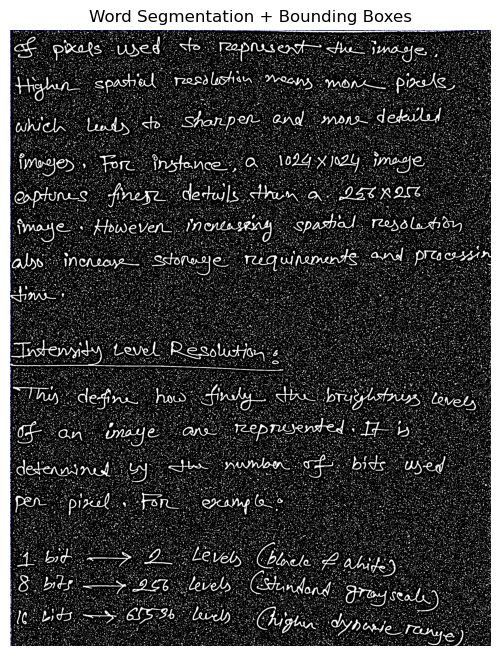

In [18]:
visualization = cv2.cvtColor(
    binary,
    cv2.COLOR_GRAY2BGR
)

for segment in segments:

    x1 = segment["x1"]
    y1 = segment["y1"]
    x2 = segment["x2"]
    y2 = segment["y2"]

    line_no = segment["line_no"]
    word_no = segment["word_no"]

    cv2.rectangle(
        visualization,
        (x1, y1),
        (x2, y2),
        (255, 0, 0),
        1
    )

    cv2.putText(
        visualization,
        f"{line_no}.{word_no}",
        (x1, max(10, y1 - 2)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.3,
        (255, 0, 0),
        1
    )


plt.figure(figsize=(12, 8))

plt.imshow(
    cv2.cvtColor(
        visualization,
        cv2.COLOR_BGR2RGB
    )
)

plt.title(
    "Word Segmentation + Bounding Boxes"
)

plt.axis("off")

plt.show()

# create segmentation record for all images

In [19]:
segmentation_records = []

failed_segmentation = []

for _, row in tqdm(
    metadata.iterrows(),
    total=len(metadata),
    desc="Segmenting images"
):

    image_path = (
        PROCESSED_DATASET_PATH /
        row["processed_image_path"]
    )

    try:

        image = cv2.imread(
            str(image_path),
            cv2.IMREAD_GRAYSCALE
        )

        if image is None:
            raise ValueError(
                "Could not read image"
            )

        binary = prepare_binary_image(
            image
        )

        segments = segment_image(
            binary,
            line_threshold_ratio=0.05,
            min_line_height=2,
            min_word_gap=8,
            min_word_width=3
        )

        for segment in segments:

            segmentation_records.append({

                "image_path":
                    row["processed_image_path"],

                "image_name":
                    row["image_name"],

                "writer_id":
                    row["writer_id"],

                "sample_id":
                    row["sample_id"],

                "split":
                    row["split"],

                "line_no":
                    segment["line_no"],

                "word_no":
                    segment["word_no"],

                "x1":
                    segment["x1"],

                "y1":
                    segment["y1"],

                "x2":
                    segment["x2"],

                "y2":
                    segment["y2"],

                "width":
                    segment["width"],

                "height":
                    segment["height"]
            })

    except Exception as e:

        failed_segmentation.append({

            "image_path":
                str(image_path),

            "error":
                str(e)
        })


segmentation_df = pd.DataFrame(
    segmentation_records
)

print(
    "Total word segments:",
    len(segmentation_df)
)

print(
    "Images successfully segmented:",
    segmentation_df["image_path"].nunique()
)

Segmenting images:   0%|          | 0/1305 [00:00<?, ?it/s]

Total word segments: 216975
Images successfully segmented: 1305


In [20]:
display(
    segmentation_df.head(20)
)

,image_path,image_name,writer_id,sample_id,split,line_no,word_no,x1,y1,x2,y2,width,height
0,S01/aug_10_sample2.png,aug_10_sample2.jpg,S01,1,test,1,1,0,0,2013,2579,2013,2579
1,S01/aug_1_sample1.png,aug_1_sample1.jpg,S01,2,test,1,1,0,0,5,2,5,2
2,S01/aug_1_sample1.png,aug_1_sample1.jpg,S01,2,test,1,2,17,0,21,2,4,2
3,S01/aug_1_sample1.png,aug_1_sample1.jpg,S01,2,test,1,3,75,0,79,2,4,2
4,S01/aug_1_sample1.png,aug_1_sample1.jpg,S01,2,test,1,4,845,0,851,2,6,2
5,S01/aug_1_sample1.png,aug_1_sample1.jpg,S01,2,test,1,5,882,0,885,2,3,2
6,S01/aug_1_sample1.png,aug_1_sample1.jpg,S01,2,test,1,6,895,0,902,2,7,2
7,S01/aug_1_sample1.png,aug_1_sample1.jpg,S01,2,test,1,7,911,0,926,2,15,2
8,S01/aug_1_sample1.png,aug_1_sample1.jpg,S01,2,test,1,8,940,0,948,2,8,2
9,S01/aug_1_sample1.png,aug_1_sample1.jpg,S01,2,test,2,1,0,43,174,133,174,90


In [21]:
SEGMENTATION_PATH = Path(
    r"C:\Users\SWARA\Documents\Handwriting Analysis\features\segmentation_coordinates.csv"
)

SEGMENTATION_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

segmentation_df.to_csv(
    SEGMENTATION_PATH,
    index=False
)

print(
    "Segmentation coordinates saved to:"
)

print(
    SEGMENTATION_PATH
)

Segmentation coordinates saved to:
C:\Users\SWARA\Documents\Handwriting Analysis\features\segmentation_coordinates.csv


In [22]:
WORD_SEGMENTS_PATH = (
    PROCESSED_DATASET_PATH / "word_segments"
)

WORD_SEGMENTS_PATH.mkdir(
    parents=True,
    exist_ok=True
)

print(
    "Word segment directory:",
    WORD_SEGMENTS_PATH
)

Word segment directory: C:\Users\SWARA\Documents\Handwriting Analysis\dataset\processed\word_segments


In [23]:
saved_words = 0

for _, segment in tqdm(
    segmentation_df.iterrows(),
    total=len(segmentation_df),
    desc="Saving word segments"
):

    image_path = (
        PROCESSED_DATASET_PATH /
        segment["image_path"]
    )

    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        continue

    x1 = int(segment["x1"])
    y1 = int(segment["y1"])
    x2 = int(segment["x2"])
    y2 = int(segment["y2"])

    word = image[
        y1:y2,
        x1:x2
    ]

    writer = segment["writer_id"]

    output_folder = (
        WORD_SEGMENTS_PATH / writer
    )

    output_folder.mkdir(
        parents=True,
        exist_ok=True
    )

    output_name = (
        f"{segment['image_name']}"
        f"_L{segment['line_no']}"
        f"_W{segment['word_no']}.png"
    )

    output_path = (
        output_folder /
        output_name
    )

    cv2.imwrite(
        str(output_path),
        word
    )

    saved_words += 1


print(
    "Word images saved:",
    saved_words
)

Saving word segments:   0%|          | 0/216975 [00:00<?, ?it/s]

Word images saved: 216975


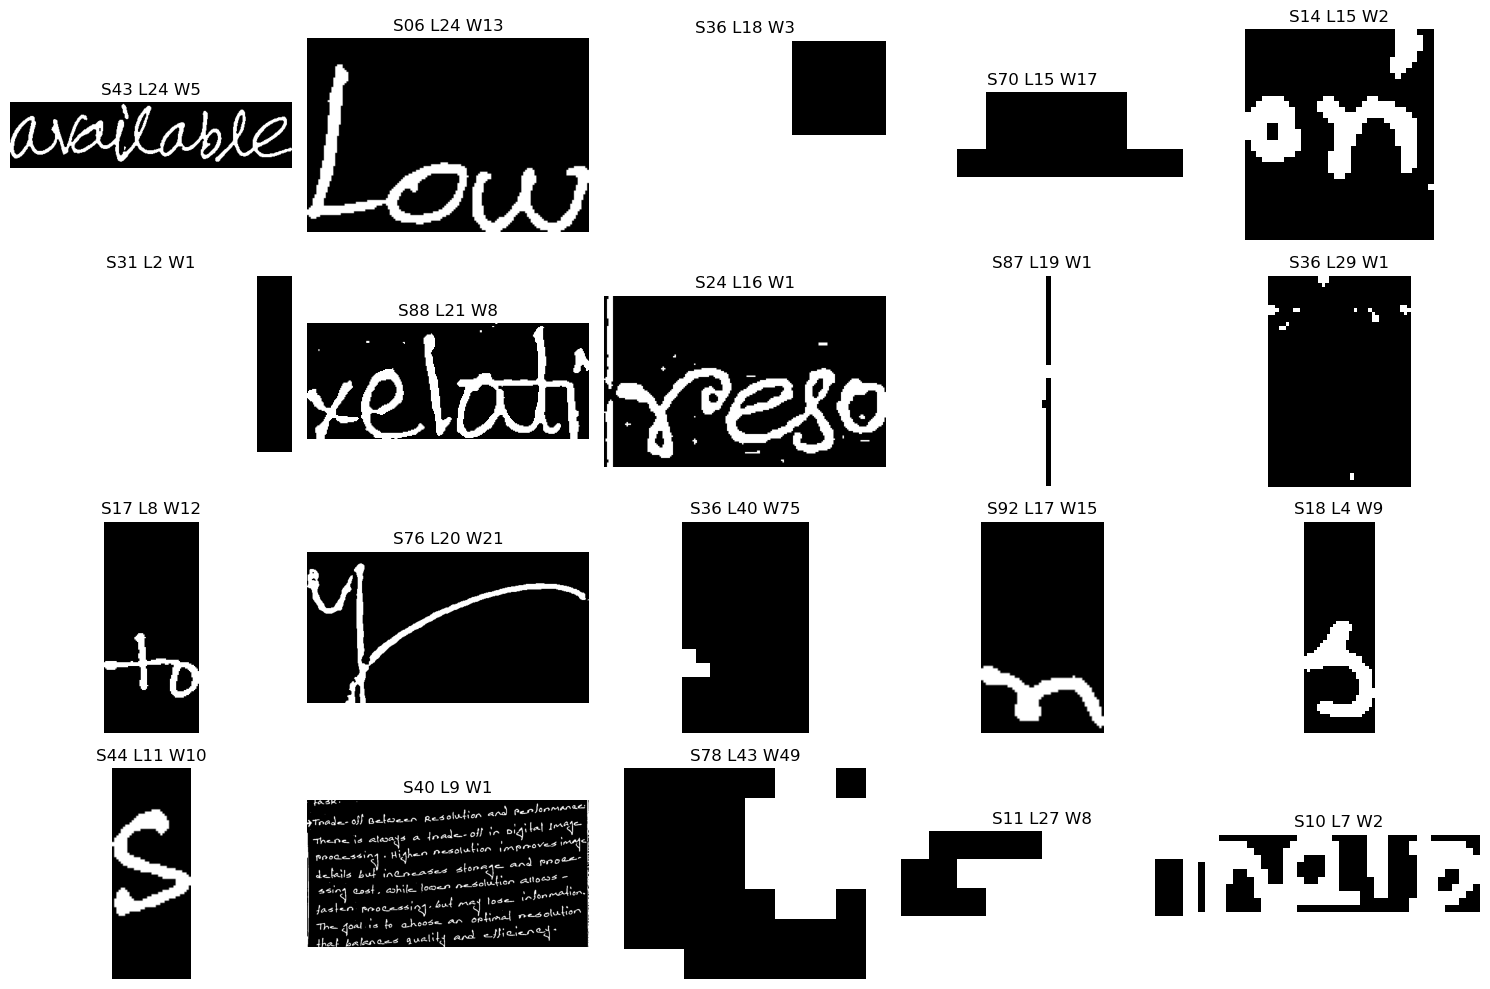

In [24]:
sample_segments = segmentation_df.sample(
    min(20, len(segmentation_df)),
    random_state=42
)

fig, axes = plt.subplots(
    4,
    5,
    figsize=(15, 10)
)

for ax, (_, segment) in zip(
    axes.ravel(),
    sample_segments.iterrows()
):

    image_path = (
        PROCESSED_DATASET_PATH /
        segment["image_path"]
    )

    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE
    )

    x1 = int(segment["x1"])
    y1 = int(segment["y1"])
    x2 = int(segment["x2"])
    y2 = int(segment["y2"])

    word = image[
        y1:y2,
        x1:x2
    ]

    ax.imshow(
        word,
        cmap="gray"
    )

    ax.set_title(
        f"{segment['writer_id']} "
        f"L{segment['line_no']} "
        f"W{segment['word_no']}"
    )

    ax.axis("off")


plt.tight_layout()
plt.show()

In [25]:
print("======================================")
print("SEGMENTATION STATISTICS")
print("======================================")

print(
    "Total images:",
    segmentation_df["image_path"].nunique()
)

print(
    "Total lines:",
    segmentation_df[
        ["image_path", "line_no"]
    ].drop_duplicates().shape[0]
)

print(
    "Total words:",
    len(segmentation_df)
)

print(
    "\nAverage words per image:"
)

words_per_image = (
    segmentation_df
    .groupby("image_path")
    .size()
)

print(
    words_per_image.mean()
)

print(
    "\nAverage words per line:"
)

words_per_line = (
    segmentation_df
    .groupby(
        ["image_path", "line_no"]
    )
    .size()
)

print(
    words_per_line.mean()
)

SEGMENTATION STATISTICS
Total images: 1305
Total lines: 18812
Total words: 216975

Average words per image:
166.26436781609195

Average words per line:
11.533861365086116
